Write a program to sharpen the input image using:
1. Laplacian filter
2. Gradient operators of Sobel and Canny edge detector
3. Unsharp masking. To obtain blurred image, use the Gaussian filter of size 5x5
and sigma= 3


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ------------------------------------------------------------
# 1. Upload Input Image
# ------------------------------------------------------------

print("Upload the input image:")
uploaded = files.upload()

filename = next(iter(uploaded))

# Read image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Image could not be loaded.")

# Convert BGR to RGB for displaying
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print("\nImage loaded successfully.")
print("Image size:", gray.shape)
# ============================================================
# 2. LAPLACIAN FILTER
# ============================================================

# Apply Laplacian operator
laplacian = cv2.Laplacian(
    gray,
    cv2.CV_64F
)

# Convert absolute values to 8-bit
laplacian = cv2.convertScaleAbs(laplacian)

# Sharpen image using Laplacian
laplacian_sharpened = cv2.addWeighted(
    gray,
    1.0,
    laplacian,
    -1.0,
    0
)


Upload the input image:


Saving Spider Lily.jpeg to Spider Lily.jpeg

Image loaded successfully.
Image size: (1307, 736)


In [2]:
# ============================================================
# 3. SOBEL GRADIENT OPERATOR
# ============================================================

# Sobel in X direction
sobel_x = cv2.Sobel(
    gray,
    cv2.CV_64F,
    1,
    0,
    ksize=3
)

# Sobel in Y direction
sobel_y = cv2.Sobel(
    gray,
    cv2.CV_64F,
    0,
    1,
    ksize=3
)

# Calculate gradient magnitude
sobel_magnitude = np.sqrt(
    sobel_x**2 + sobel_y**2
)

# Normalize to 0-255
sobel_magnitude = cv2.normalize(
    sobel_magnitude,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Sharpen using Sobel gradient
sobel_sharpened = cv2.addWeighted(
    gray,
    1.0,
    sobel_magnitude,
    1.0,
    0
)

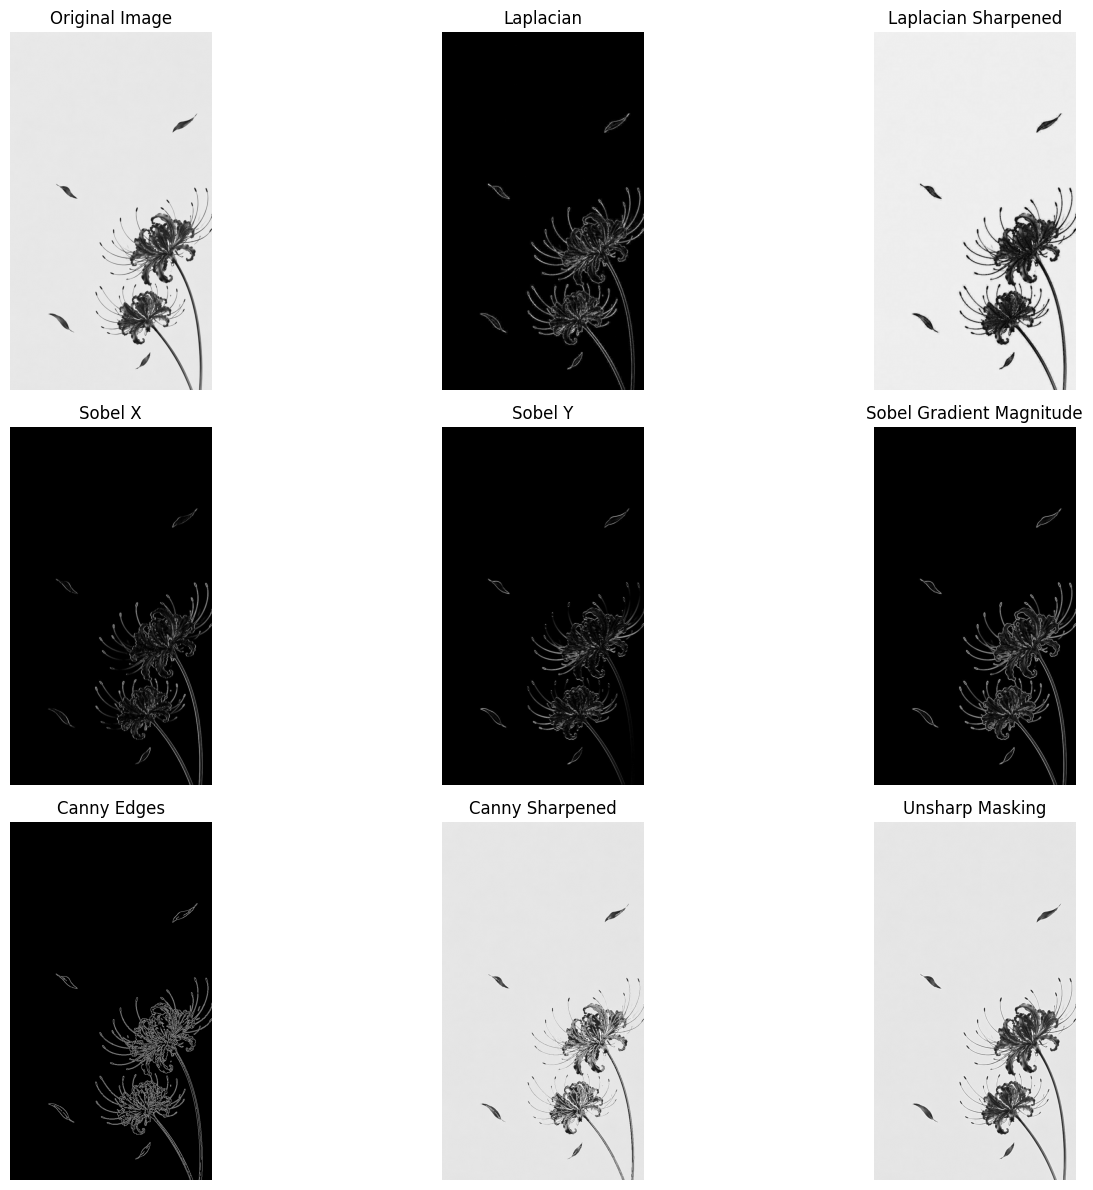

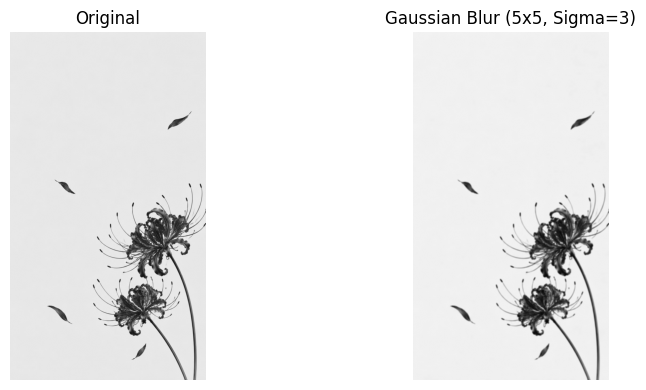


All sharpened images have been saved.


In [3]:
# ============================================================
# 4. CANNY EDGE DETECTOR
# ============================================================

# Apply Canny edge detection
canny_edges = cv2.Canny(
    gray,
    threshold1=100,
    threshold2=200
)

# Sharpen image using Canny edges
canny_sharpened = cv2.addWeighted(
    gray,
    1.0,
    canny_edges,
    1.0,
    0
)


# ============================================================
# 5. UNSHARP MASKING
# ============================================================

# Gaussian blur:
# Kernel size = 5x5
# Sigma = 3

blurred = cv2.GaussianBlur(
    gray,
    (5, 5),
    3
)

# Create mask
mask = cv2.subtract(
    gray,
    blurred
)

# Add mask to original image
unsharp = cv2.addWeighted(
    gray,
    1.0,
    mask,
    1.0,
    0
)


# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

plt.figure(figsize=(15, 12))

# Original
plt.subplot(3, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title("Original Image")
plt.axis("off")

# Laplacian
plt.subplot(3, 3, 2)
plt.imshow(laplacian, cmap='gray')
plt.title("Laplacian")
plt.axis("off")

# Laplacian sharpened
plt.subplot(3, 3, 3)
plt.imshow(laplacian_sharpened, cmap='gray')
plt.title("Laplacian Sharpened")
plt.axis("off")

# Sobel X
plt.subplot(3, 3, 4)
plt.imshow(np.abs(sobel_x), cmap='gray')
plt.title("Sobel X")
plt.axis("off")

# Sobel Y
plt.subplot(3, 3, 5)
plt.imshow(np.abs(sobel_y), cmap='gray')
plt.title("Sobel Y")
plt.axis("off")

# Sobel magnitude
plt.subplot(3, 3, 6)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title("Sobel Gradient Magnitude")
plt.axis("off")

# Canny
plt.subplot(3, 3, 7)
plt.imshow(canny_edges, cmap='gray')
plt.title("Canny Edges")
plt.axis("off")

# Canny sharpened
plt.subplot(3, 3, 8)
plt.imshow(canny_sharpened, cmap='gray')
plt.title("Canny Sharpened")
plt.axis("off")

# Unsharp masking
plt.subplot(3, 3, 9)
plt.imshow(unsharp, cmap='gray')
plt.title("Unsharp Masking")
plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 7. DISPLAY GAUSSIAN BLURRED IMAGE
# ============================================================

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred, cmap='gray')
plt.title("Gaussian Blur (5x5, Sigma=3)")
plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 8. SAVE RESULTS
# ============================================================

cv2.imwrite("laplacian_sharpened.jpg", laplacian_sharpened)
cv2.imwrite("sobel_sharpened.jpg", sobel_sharpened)
cv2.imwrite("canny_sharpened.jpg", canny_sharpened)
cv2.imwrite("unsharp_masking.jpg", unsharp)

print("\nAll sharpened images have been saved.")